# Classificação de espécies de Iris com KNN

**Objetivo:** treinar um modelo de machine learning que identifica a espécie de uma flor Iris (*setosa*, *versicolor* ou *virginica*) a partir de 4 medidas: comprimento e largura da sépala e da pétala.

**Dataset:** Iris, que vem com o Scikit-Learn. São 150 flores, 50 de cada espécie, e nenhum valor faltando.

**O que este notebook faz:**
1. Explora os dados com tabelas e gráficos
2. Separa os dados em treino e teste
3. Escolhe o número de vizinhos (`k`) do KNN com validação cruzada
4. Compara o KNN com outros dois modelos
5. Avalia o modelo final com acurácia, relatório de classificação e matriz de confusão
6. Salva o modelo para ser usado pelo script `prever.py`

**Resultado:** KNN com `k = 5`, com **97,5% de acurácia média na validação cruzada** e **100% no conjunto de teste** (30 de 30 flores). Os poucos erros acontecem entre *versicolor* e *virginica*, as duas espécies mais parecidas.

## 1. Importação das bibliotecas

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# pastas onde o notebook salva as imagens e o modelo (relativas à pasta notebooks/)
PASTA_IMAGENS = Path("../imagens")
PASTA_MODELO = Path("../modelo")
PASTA_IMAGENS.mkdir(exist_ok=True)
PASTA_MODELO.mkdir(exist_ok=True)

# usado em todos os sorteios para que os resultados sejam sempre os mesmos
SEMENTE = 42

## 2. Carregamento dos dados

In [ ]:
iris = load_iris()

print("Características (medidas):", iris.feature_names)
print("Classes (espécies):", iris.target_names.tolist())

Características (medidas): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes (espécies): ['setosa', 'versicolor', 'virginica']


In [3]:
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df["target"] = iris.target

# coluna só para leitura: o nome da espécie em vez do número
df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Análise exploratória

In [4]:
print("Linhas e colunas:", df.shape)
print("Valores faltando:", df.isna().sum().sum())

df.describe().round(2)

Linhas e colunas: (150, 6)
Valores faltando: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


In [5]:
df["especie"].value_counts()

especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

As três espécies têm exatamente 50 flores cada, ou seja, as classes estão **equilibradas**. Por isso a acurácia é uma métrica justa aqui: um modelo que "chutasse" sempre a mesma espécie acertaria só 33%.

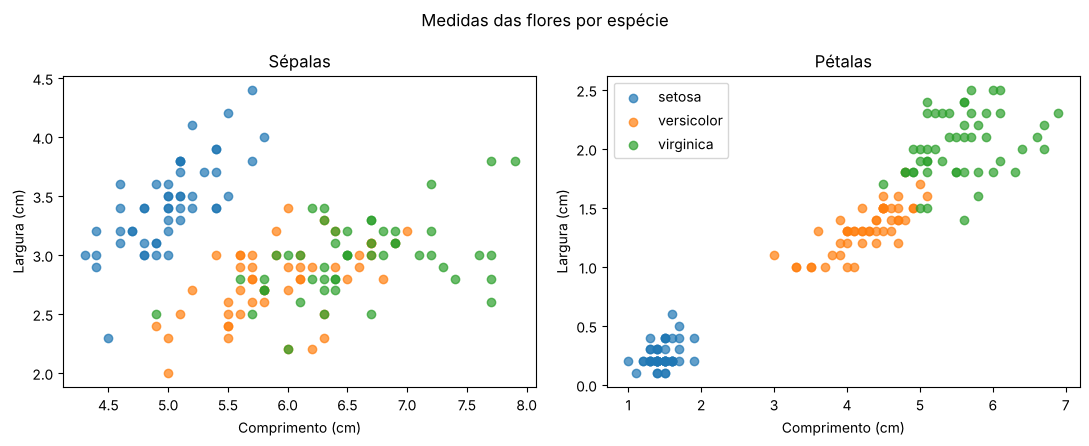

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
cores = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}

for especie, grupo in df.groupby("especie"):
    eixos[0].scatter(grupo["sepal length (cm)"], grupo["sepal width (cm)"],
                     label=especie, color=cores[especie], alpha=0.7)
    eixos[1].scatter(grupo["petal length (cm)"], grupo["petal width (cm)"],
                     label=especie, color=cores[especie], alpha=0.7)

eixos[0].set(title="Sépalas", xlabel="Comprimento (cm)", ylabel="Largura (cm)")
eixos[1].set(title="Pétalas", xlabel="Comprimento (cm)", ylabel="Largura (cm)")
eixos[1].legend()
fig.suptitle("Medidas das flores por espécie")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "dispersao_medidas.png", dpi=120)

**O que o gráfico mostra:**
- Nas **pétalas** (à direita), a *setosa* fica totalmente separada das outras duas: pétalas bem menores. Qualquer modelo deve acertá-la sempre.
- *Versicolor* e *virginica* ficam próximas e se sobrepõem um pouco. **Se o modelo errar, deve ser entre essas duas.**
- Nas **sépalas** (à esquerda), as espécies se misturam muito mais. As medidas das pétalas são as que mais ajudam a separar as espécies.

## 4. Separação em treino e teste

In [7]:
# X guarda as características das flores (as 4 medidas)
# y guarda a classificação correta de cada flor (target), ou seja, a espécie
# axis=1 indica que estamos removendo colunas (axis=0 removeria linhas)
X = df.drop(columns=["target", "especie"])
y = df["target"]

# 80% para treino e 20% para teste
# stratify=y mantém a mesma proporção de cada espécie nos dois grupos
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=y
)

print("Flores para treino:", len(X_treino))
print("Flores para teste:", len(X_teste))
print("Espécies no teste:", y_teste.value_counts().sort_index().tolist())

Flores para treino: 120
Flores para teste: 30
Espécies no teste: [10, 10, 10]


## 5. Escolha do número de vizinhos (k)

O KNN classifica uma flor nova olhando para as `k` flores mais parecidas que ele já conhece. Mas qual `k` usar?

Em vez de escolher no chute, testei de 1 a 15 com **validação cruzada**: os dados de treino são divididos em 5 partes, e o modelo é treinado 5 vezes, cada vez testando numa parte diferente. A média dessas 5 notas é mais confiável do que um único teste com só 30 flores.

O conjunto de teste **não** é usado aqui. Ele fica guardado para a avaliação final.

Melhor k: 5 (acurácia média de 97.5% na validação cruzada)


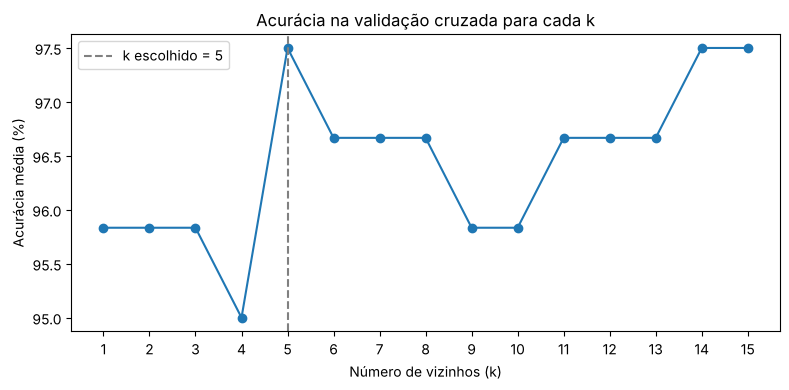

In [8]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

valores_k = range(1, 16)
medias = []
for k in valores_k:
    notas = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_treino, y_treino, cv=validacao)
    medias.append(notas.mean())

resultados_k = pd.Series(medias, index=valores_k, name="acuracia_media")

# em caso de empate, idxmax() devolve o menor k (modelo mais simples)
melhor_k = int(resultados_k.idxmax())
print(f"Melhor k: {melhor_k} (acurácia média de {resultados_k.max():.1%} na validação cruzada)")

fig, eixo = plt.subplots(figsize=(8, 4))
eixo.plot(resultados_k.index, resultados_k.values * 100, marker="o")
eixo.axvline(melhor_k, color="gray", linestyle="--", label=f"k escolhido = {melhor_k}")
eixo.set(title="Acurácia na validação cruzada para cada k",
         xlabel="Número de vizinhos (k)", ylabel="Acurácia média (%)", xticks=list(valores_k))
eixo.legend()
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "escolha_k.png", dpi=120)

## 6. Comparação com outros modelos

Para saber se o KNN é uma boa escolha, comparei com dois modelos clássicos, usando a mesma validação cruzada.

In [9]:
modelos = {
    f"KNN (k={melhor_k})": KNeighborsClassifier(n_neighbors=melhor_k),
    "Árvore de decisão": DecisionTreeClassifier(random_state=SEMENTE),
    "Regressão logística": LogisticRegression(max_iter=1000),
}

linhas = []
for nome, modelo_teste in modelos.items():
    notas = cross_val_score(modelo_teste, X_treino, y_treino, cv=validacao)
    linhas.append({"modelo": nome,
                   "acuracia_media_%": round(notas.mean() * 100, 1),
                   "desvio_padrao_%": round(notas.std() * 100, 1)})

comparacao = pd.DataFrame(linhas).sort_values("acuracia_media_%", ascending=False)
comparacao

,modelo,acuracia_media_%,desvio_padrao_%
0,KNN (k=5),97.5,2.0
2,Regressão logística,95.8,2.6
1,Árvore de decisão,95.0,1.7


O KNN teve a maior acurácia média (97,5%), mas a diferença para os outros modelos é pequena (1,7 a 2,5 pontos percentuais) e fica dentro do desvio padrão. Com um dataset deste tamanho, os três modelos são praticamente equivalentes.

Mantive o **KNN** porque, além de ter o melhor resultado, é simples de entender e de explicar: a espécie de uma flor nova é decidida pela maioria das 5 flores mais parecidas.

## 7. Treino final e avaliação no conjunto de teste

In [10]:
modelo = KNeighborsClassifier(n_neighbors=melhor_k)
modelo.fit(X_treino, y_treino)

previsoes = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, previsoes)
erros = int((previsoes != y_teste).sum())

print(f"Acurácia no teste: {acuracia:.1%} ({len(y_teste) - erros} acertos de {len(y_teste)})")
print()
print(classification_report(y_teste, previsoes, target_names=iris.target_names, digits=3))

Acurácia no teste: 100.0% (30 acertos de 30)

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



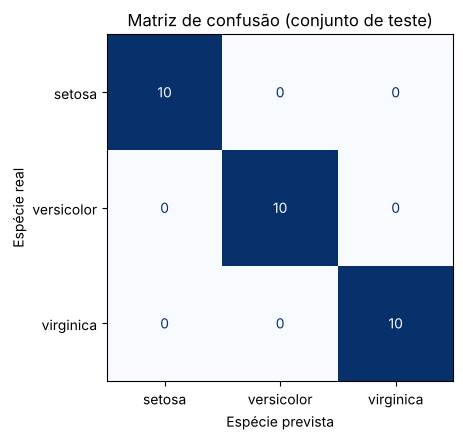

In [11]:
fig, eixo = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes, display_labels=iris.target_names, cmap="Blues", ax=eixo, colorbar=False
)
eixo.set(title="Matriz de confusão (conjunto de teste)", xlabel="Espécie prevista", ylabel="Espécie real")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "matriz_confusao.png", dpi=120)

O modelo acertou **todas as 30 flores** do teste: a matriz de confusão só tem valores na diagonal.

Mas **100% não significa que o modelo nunca erra.** O teste tem só 30 flores, então um único erro já derrubaria a acurácia para 96,7%. A estimativa mais realista é a da validação cruzada (97,5%). Abaixo estão os erros que o modelo cometeu na validação cruzada, dentro dos dados de treino:

In [12]:
previsoes_validacao = cross_val_predict(
    KNeighborsClassifier(n_neighbors=melhor_k), X_treino, y_treino, cv=validacao
)

pd.DataFrame(
    confusion_matrix(y_treino, previsoes_validacao),
    index=[f"real: {nome}" for nome in iris.target_names],
    columns=[f"previsto: {nome}" for nome in iris.target_names],
)

,previsto: setosa,previsto: versicolor,previsto: virginica
real: setosa,40,0,0
real: versicolor,0,38,2
real: virginica,0,1,39


Foram 3 erros em 120 flores, **todos entre *versicolor* e *virginica***, exatamente como o gráfico de dispersão da seção 3 indicava. A *setosa* nunca foi confundida.

## 8. Classificando uma flor nova

As medidas precisam estar num DataFrame com os mesmos nomes de colunas usados no treino. Se passarmos uma lista simples, o Scikit-Learn mostra um aviso de que os nomes das características não batem.

In [13]:
nova_flor = pd.DataFrame([[6.3, 3.3, 6.0, 2.5]], columns=iris.feature_names)

especie_prevista = iris.target_names[modelo.predict(nova_flor)[0]]
probabilidades = modelo.predict_proba(nova_flor)[0]

print("Espécie identificada:", especie_prevista)
for especie, prob in zip(iris.target_names, probabilidades):
    print(f"  {especie}: {prob:.0%}")

Espécie identificada: virginica
  setosa: 0%
  versicolor: 0%
  virginica: 100%


**Cuidado com medidas fora da realidade.** O modelo *sempre* devolve uma espécie, mesmo para medidas impossíveis. Por exemplo, uma flor com pétala de 9 cm de comprimento e 0,2 cm de largura não existe no dataset (a maior pétala tem 6,9 cm), mas o modelo classifica mesmo assim:

In [14]:
flor_estranha = pd.DataFrame([[4.0, 2.0, 9.0, 0.2]], columns=iris.feature_names)
print("Espécie identificada:", iris.target_names[modelo.predict(flor_estranha)[0]])

Espécie identificada: virginica


Por isso, o artefato salvo abaixo guarda também os **limites** (mínimo e máximo) de cada medida vista no treino. O script `prever.py` usa esses limites para avisar quando a flor informada está fora do que o modelo conhece.

## 9. Salvando o modelo

In [15]:
artefato = {
    "modelo": modelo,
    "nomes_classes": iris.target_names.tolist(),
    "nomes_caracteristicas": list(iris.feature_names),
    "limites": {coluna: (float(X_treino[coluna].min()), float(X_treino[coluna].max()))
                for coluna in X_treino.columns},
    "acuracia_teste": float(acuracia),
    "versao_sklearn": sklearn.__version__,
}

caminho_modelo = PASTA_MODELO / "modelo_iris.pkl"
joblib.dump(artefato, caminho_modelo)
print("Modelo salvo em:", caminho_modelo)
print("Versão do scikit-learn:", sklearn.__version__)

Modelo salvo em: ../modelo/modelo_iris.pkl
Versão do scikit-learn: 1.9.1


## 10. Conclusão

- As medidas das **pétalas** são as que mais separam as espécies. A *setosa* é sempre identificada corretamente.
- O **KNN com k = 5**, escolhido por validação cruzada, teve 97,5% de acurácia média e acertou as 30 flores do teste.
- Os erros acontecem entre *versicolor* e *virginica*, que têm medidas parecidas.
- **Limitações:** o Iris é um dataset pequeno (150 flores) e fácil, muito usado para aprender. Resultados tão altos não são comuns em problemas reais. Além disso, o modelo sempre responde uma espécie, mesmo para medidas fora da realidade; por isso o `prever.py` valida as entradas.
- **Próximos passos:** disponibilizar o modelo numa API com Flask e testar o mesmo processo num dataset maior e mais difícil.